# 1 - Logistic Regression
In this notebook, a logistic regression model will be used for forecasting electricity prices in Spain.

First, we import the required libraries for data handling, normalization, numerical computation, and visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Set random seed for consistent results
np.random.seed(42)

# 2 - Dataset Loading and Chronological Split
We load Master_Dataset_Engineered_2023_2025.xlsx (26,136 hourly observations) and divide it chronologically into:
- Training Set (2023–2024): First 17,376 rows.
- Testing Set (2025): Last 8,760 rows.


In [26]:
# Load the data
df = pd.read_excel("model_input\Master_Dataset_Engineered_2023_2025.xlsx")

#Separate the data 
input_data = df.iloc[:17376].values
input_data_2025 = df.iloc[17376:].values

# Categorizing the data into inputs (x) and outputs (y) for train and test sets
# Column 0: Datetime, Column 1: Price_EUR_MWh (y), Columns 2 to 13: x
train_set_x_orig = input_data[:, 2:].astype(float)
test_set_x_orig = input_data_2025[:, 2:].astype(float)

train_set_y_orig = input_data[:, 1:2].astype(float)
test_set_y_orig = input_data_2025[:, 1:2].astype(float)

print(f"train_set_x_orig shape: {train_set_x_orig.shape}")
print(f"train_set_y_orig shape: {train_set_y_orig.shape}")
print(f"test_set_x_orig shape:  {test_set_x_orig.shape}")
print(f"test_set_y_orig shape:  {test_set_y_orig.shape}")

train_set_x_orig shape: (17376, 12)
train_set_y_orig shape: (17376, 1)
test_set_x_orig shape:  (8760, 12)
test_set_y_orig shape:  (8760, 1)


# 3 -Normalization
To ensure stable gradient descent convergence and prevent large-magnitude variables from dominating the weights, we scale all features and target values to the (0, 1) range using MinMaxScaler.

We then transpose each array so that its dimensions follow the neural network convention (n_features, m_samples).

In [3]:

scaler = MinMaxScaler(feature_range=(0, 1))

train_set_x_normalized = scaler.fit_transform(train_set_x_orig)
test_set_x_normalized = scaler.fit_transform(test_set_x_orig)

train_set_y_normalized = scaler.fit_transform(train_set_y_orig)
test_set_y_normalized = scaler.fit_transform(test_set_y_orig)

# Transpose arrays so features are in rows and hourly samples are in columns
train_set_x_normalized = train_set_x_normalized.T
test_set_x_normalized = test_set_x_normalized.T
train_set_y_normalized = train_set_y_normalized.T
test_set_y_normalized = test_set_y_normalized.T

# Extract dataset dimensions
m_train = train_set_x_normalized.shape[1]
m_test = test_set_x_normalized.shape[1]
n_x = train_set_x_normalized.shape[0]

print(f"Number of training samples (m_train): {m_train}")
print(f"Number of testing samples (m_test):   {m_test}")
print(f"Number of input features (n_x):       {n_x}")
print(f"train_set_x_normalized shape:         {train_set_x_normalized.shape}")
print(f"train_set_y_normalized shape:         {train_set_y_normalized.shape}")

Number of training samples (m_train): 17376
Number of testing samples (m_test):   8760
Number of input features (n_x):       12
train_set_x_normalized shape:         (12, 17376)
train_set_y_normalized shape:         (1, 17376)


# 4 - Model Architecture Functions
## 4.1 - Activation Function and Parameter Initialization
We define the sigmoid activation function to map linear combinations into the $(0, 1)$ interval, along with a helper function to initialize the weight vector W with random real numbers and bias b to zero.

In [4]:
def sigmoid(z):

    s = 1/(1 + np.exp(-z))

    return s

def init_params(n_features):

    w = np.zeros((n_features, 1))
    b = 0.0
    
    return w, b

## 4.2 - Forward and backward prop


In [ ]:
def propagate(w, b, X, Y):
    m = X.shape[1] #number of columns = number of examples
    
    # Forward pass: compute activation and cost
    z = np.dot(w.T, X) + b #WX +b;     W = (nx, 1)    X = (nx,m)  That is why we need to traspose W, to allow matricial product

    A = sigmoid(z)

    cost = (-1 / m) * np.sum(Y * np.log(A) + (1 - Y) * np.log(1 - A))
    
    # Backward pass: compute gradients with respect to w and b
    dZ = A - Y
    dw = (1 / m) * np.dot(X, dZ.T)
    db = (1 / m) * np.sum(dZ)
    
    cost = float(np.squeeze(cost))
    grads = {"dw": dw, "db": db}
    
    return grads, cost

## 4.3 - Gradient descent optimization
Here, we are updating the parameters using the gradient descent method

In [6]:
def optimize(w, b, X, Y, num_iterations=2000, learning_rate=0.5, print_cost=False):
    costs = []
    
    for i in range(num_iterations):
        grads, cost = propagate(w, b, X, Y)
        
        # Gradient descent parameter update
        w = w - learning_rate * grads["dw"]
        b = b - learning_rate * grads["db"]
        
        if i % 100 == 0:
            costs.append(cost)
            if print_cost:
                print ("Cost after iteration %i: %f" %(i, cost))
                
    params = {"w": w, "b": b}
    
    return params, grads, costs



# 5 - Prediction
Usint the learned parameters, we are going to build the function that will predict the labels for our dataset

In [7]:
def predict (w, b, X):
    
    m = X.shape[1]
    Y_prediction = np.zeros((1,m))
    w = w.reshape(X.shape[0], 1) #We ensure that W has the correct dimensions (nx, 1) (number of features, number of neurons)

    z = np.dot(w.T, X) + b 
    A = sigmoid(z)

    for i in range(A.shape[1]):
        Y_prediction[0,i] = A[0,i]
    
    return Y_prediction


# 6 - Model training
Implement the model function using all the previously defined functions

In [8]:

def model(X_train, Y_train, X_test, Y_test, num_iterations=2000, learning_rate=0.5, print_cost=True):
    

    w, b = init_params(X_train.shape[0]) #Initializing w and b
    
    params, grads, costs = optimize(w, b, X_train, Y_train, num_iterations, learning_rate, print_cost)
    w, b = params["w"], params["b"]
    
    Y_pred_train = predict(w, b, X_train)
    Y_pred_test = predict(w, b, X_test)
    
    if print_cost:
        print("Train accuracy: {} %".format(100- np.mean(np.abs(Y_pred_train - Y_train))*100))
        print("Test accuracy: {} %".format(100-np.mean(np.abs(Y_pred_test - Y_test))*100))
    
    results = {
        "costs": costs,
        "Y_pred_train": Y_pred_train,
        "Y_pred_test": Y_pred_test,
        "w": w,
        "b": b,
        "learning_rate": learning_rate,
        "num_iterations": num_iterations
    }

    return results


In [9]:
logistic_regression_model = model(train_set_x_normalized, train_set_y_normalized, test_set_x_normalized, test_set_y_normalized, num_iterations = 2000, learning_rate = 0.5, print_cost = True)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.576147
Cost after iteration 200: 0.568262
Cost after iteration 300: 0.565678
Cost after iteration 400: 0.564418
Cost after iteration 500: 0.563709
Cost after iteration 600: 0.563279
Cost after iteration 700: 0.563007
Cost after iteration 800: 0.562828
Cost after iteration 900: 0.562707
Cost after iteration 1000: 0.562623
Cost after iteration 1100: 0.562564
Cost after iteration 1200: 0.562522
Cost after iteration 1300: 0.562491
Cost after iteration 1400: 0.562468
Cost after iteration 1500: 0.562451
Cost after iteration 1600: 0.562438
Cost after iteration 1700: 0.562428
Cost after iteration 1800: 0.562420
Cost after iteration 1900: 0.562414
Train accuracy: 92.84556025147106 %
Test accuracy: 93.72388590850758 %


# Cost function
Plot of the cost function 

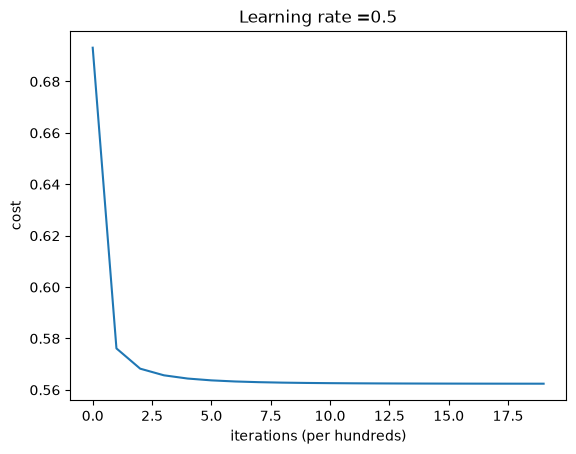

In [10]:
costs = np.squeeze(logistic_regression_model['costs'])
plt.plot(costs)
plt.ylabel('cost')
plt.xlabel('iterations (per hundreds)') #the reason of this way of plotting is the way we defined optimize function (Only stores a value for cost every 100 iterations)
plt.title("Learning rate =" + str(logistic_regression_model["learning_rate"]))
plt.show()

# Denormalizing 

In [11]:
#Reverse normalization
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Reverse the normalization to get the original data
Y_prediction_test_real_scale = scaler.inverse_transform(logistic_regression_model["Y_pred_test"])


# Results

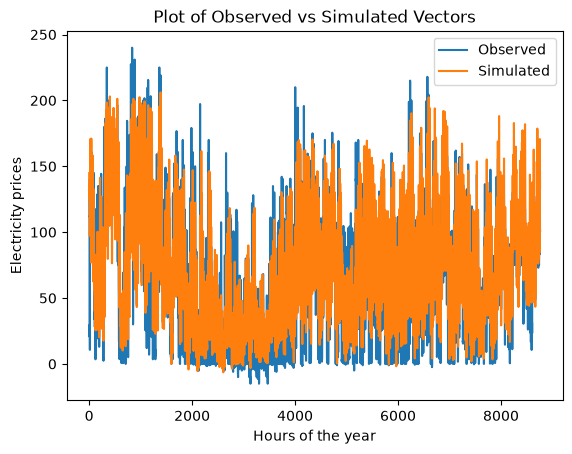

In [12]:
import matplotlib.pyplot as plt
import numpy as np

# Define the two vectors

x = np.arange(0,8760, 1)
y1 = test_set_y_orig
y2 = Y_prediction_test_real_scale.T


# Plot the vectors
plt.plot(x, y1, label='Observed')
plt.plot(x, y2, label='Simulated')

# Add a title and labels for the x and y axes
plt.title('Plot of Observed vs Simulated Vectors')
plt.xlabel('Hours of the year')
plt.ylabel('Electricity prices')

# Set the y-axis limits
plt.ylim()

# Add a legend
plt.legend()

# Display the plot
plt.show()

In [13]:
feature_names = df.columns[2:].tolist()

weights_df = pd.DataFrame({
    "Feature": feature_names,
    "Weight": logistic_regression_model["w"].flatten()
})

print(weights_df)


                  Feature    Weight
0        Load_Forecast_MW  1.161740
1     Hydro_Reservoir_MWh -0.484755
2   Nuclear_Generation_MW  0.127684
3         Wind_Onshore_MW -2.076608
4                Solar_MW -1.096755
5              Price_t_24  1.398893
6              Price_t_48  0.294448
7             Price_t_168  0.993082
8            Price_24h_MA  0.356212
9                    Hour  0.028171
10                  Month  0.068228
11             Is_Weekend -0.199594


# 7 - Hyperparameter Optimization 
First, Grid Search

In [14]:
print(train_set_x_orig.shape[1])

12


In [15]:


#define the data we will use for validation

#First half for hyperparameter optimization, second half for test the best combination

X_val_norm = test_set_x_normalized[:, :4380]
Y_val_norm = test_set_y_normalized[:, :4380]
y_val_orig = test_set_y_orig[:4380, :]

#Second half:

X_test_final_norm = test_set_x_normalized[:, 4380:] 
Y_test_final_norm = test_set_y_normalized[:, 4380:]
y_test_final_orig = test_set_y_orig[4380:, :]

#we define the different hyperparameters we will try with

learning_rates = [0.01, 0.025, 0.1, 0.5, 0.75, 0.85, 1.0]
iterations_list = [500, 1000, 2000, 3000]

#we will save the results in this list:

grid_results = []

#loop for grid search

for lr in learning_rates:
    for n_iter in iterations_list:

        w, b = init_params(train_set_x_orig.shape[1])
        params, grads, cost = optimize(w, b, train_set_x_normalized, train_set_y_normalized, num_iterations = n_iter, learning_rate = lr, print_cost = False)
        
        #then, we predict in the train (23-24) and in validation (first half 2025)

        Y_pred_train = predict(params["w"], params["b"], train_set_x_normalized) 
        Y_pred_val   = predict(params["w"], params["b"], X_val_norm)

        #we calculate accuracy and MAE/RMSE in first half 2025

        train_acc = 100 -np.mean(np.abs(Y_pred_train - train_set_y_normalized))*100
        val_acc = 100 - np.mean(np.abs(Y_pred_val - Y_val_norm))*100

        y_pred_val_eur = scaler.inverse_transform(Y_pred_val.T)
        val_mae  = np.mean(np.abs(y_pred_val_eur - y_val_orig))
        val_rmse = np.sqrt(np.mean((y_pred_val_eur - y_val_orig) ** 2))

        grid_results.append({
            "Learning_Rate": lr,
            "Iterations": n_iter,
            "Final_Cost": cost[-1],
            "Train_Acc (%)": round(train_acc, 2),
            "Val_Acc (%)": round(val_acc, 2),
            "Val_MAE (EUR/MWh)": round(val_mae, 2),
            "Val_RMSE (EUR/MWh)": round(val_rmse, 2)
        })

df_grid = pd.DataFrame(grid_results)
best_row = df_grid.loc[df_grid["Val_MAE (EUR/MWh)"].idxmin()]

print(df_grid.to_string(index = False))
print("Best hyperparameters in validation (1st Half 2025):  ")
print(best_row)



 Learning_Rate  Iterations  Final_Cost  Train_Acc (%)  Val_Acc (%)  Val_MAE (EUR/MWh)  Val_RMSE (EUR/MWh)
         0.010         500    0.635559          84.45        82.39              44.91               50.79
         0.010        1000    0.618512          86.10        84.47              39.60               44.68
         0.010        2000    0.598095          88.35        87.29              32.41               36.83
         0.010        3000    0.587108          89.69        89.03              27.98               32.37
         0.025         500    0.615786          86.79        85.32              37.44               42.27
         0.025        1000    0.593510          89.10        88.26              29.93               34.29
         0.025        2000    0.577067          91.04        90.85              23.34               28.07
         0.025        3000    0.571279          91.75        91.84              20.82               25.88
         0.100         500    0.580135        

Now we try with Randomized Search

In [16]:
np.random.seed(42)

#define the data we will use for validation

#First half for hyperparameter optimization, second half for test the best combination

X_val_norm = test_set_x_normalized[:, :4380]
Y_val_norm = test_set_y_normalized[:, :4380]
y_val_orig = test_set_y_orig[:4380, :]

#Second half:

X_test_final_norm = test_set_x_normalized[:, 4380:] 
Y_test_final_norm = test_set_y_normalized[:, 4380:]
y_test_final_orig = test_set_y_orig[4380:, :]

n_search = 30

random_results = []

for i in range(n_search):
    lr = round(np.random.uniform(0.01, 1), 4)
    n_iter = int(np.random.randint(500,3500))

    w, b = init_params(train_set_x_orig.shape[1])
    params, grads, cost = optimize(w, b, train_set_x_normalized, train_set_y_normalized, num_iterations=n_iter, learning_rate=lr, print_cost = False)

    Y_pred_train = predict(params["w"], params["b"], train_set_x_normalized)
    Y_pred_val = predict(params["w"], params["b"], X_val_norm)

    train_acc = 100 -np.mean(np.abs(Y_pred_train - train_set_y_normalized))*100
    val_acc = 100 - np.mean(np.abs(Y_pred_val - Y_val_norm))*100

    y_pred_val_eur = scaler.inverse_transform(Y_pred_val.T)
    val_mae  = np.mean(np.abs(y_pred_val_eur - y_val_orig))
    val_rmse = np.sqrt(np.mean((y_pred_val_eur - y_val_orig) ** 2))

    random_results.append({
            "Learning_Rate": lr,
            "Iterations": n_iter,
            "Final_Cost": cost[-1],
            "Train_Acc (%)": round(train_acc, 2),
            "Val_Acc (%)": round(val_acc, 2),
            "Val_MAE (EUR/MWh)": round(val_mae, 2),
            "Val_RMSE (EUR/MWh)": round(val_rmse, 2)
        })

df_random = pd.DataFrame(random_results)
best_random_row = df_random.loc[df_random["Val_MAE (EUR/MWh)"].idxmin()]
print(df_random.to_string(index = False))
print("\nBest hyperparameters in validation (Randomized Search):")
print(best_random_row)



 Learning_Rate  Iterations  Final_Cost  Train_Acc (%)  Val_Acc (%)  Val_MAE (EUR/MWh)  Val_RMSE (EUR/MWh)
        0.3808        1360    0.562631          92.83        93.57              16.40               21.36
        0.1916        1595    0.563371          92.76        93.38              16.88               21.88
        0.6027        2138    0.562395          92.85        93.68              16.11               21.10
        0.4514        1738    0.562446          92.84        93.64              16.22               21.19
        0.0675        2635    0.564946          92.55        93.00              17.85               22.99
        0.3404        3419    0.562399          92.85        93.67              16.13               21.11
        0.7110        2185    0.562390          92.85        93.69              16.09               21.09
        0.0658        2891    0.564742          92.59        93.06              17.69               22.82
        0.8341        3353    0.562385        

## Evaluation of test set/performance (2nd half 2025)



In [17]:
#define the data we will use for validation

#First half for hyperparameter optimization, second half for test the best combination

X_val_norm = test_set_x_normalized[:, :4380]
Y_val_norm = test_set_y_normalized[:, :4380]
y_val_orig = test_set_y_orig[:4380, :]

#Second half:

X_test_final_norm = test_set_x_normalized[:, 4380:] 
Y_test_final_norm = test_set_y_normalized[:, 4380:]
y_test_final_orig = test_set_y_orig[4380:, :]

#we define the different hyperparameters we will try with

best_lr = float(best_row["Learning_Rate"])
best_iter = int(best_row["Iterations"])

w_best, b_best = init_params(train_set_x_orig.shape[1])

params_best, grads_best, cost_best = optimize(
    w_best, b_best,
    train_set_x_normalized, train_set_y_normalized,
    num_iterations = best_iter,  
    learning_rate  = best_lr,  
    print_cost = False
)

Y_pred_test_final = predict(params_best["w"], params_best["b"], X_test_final_norm)

test_final_acc  = 100 - np.mean(np.abs(Y_pred_test_final - Y_test_final_norm)) * 100

y_pred_test_final_eur = scaler.inverse_transform(Y_pred_test_final.T)  
test_final_mae  = np.mean(np.abs(y_pred_test_final_eur - y_test_final_orig))
test_final_rmse = np.sqrt(np.mean((y_pred_test_final_eur - y_test_final_orig) ** 2))



print(f"Hyperparameters used -> Learning Rate: {best_lr} | Iterations: {best_iter}")
print(f"Final Test Accuracy: {test_final_acc:.2f} %")
print(f"Final Test MAE:      {test_final_mae:.2f} EUR/MWh")
print(f"Final Test RMSE:     {test_final_rmse:.2f} EUR/MWh")


Hyperparameters used -> Learning Rate: 0.85 | Iterations: 3000
Final Test Accuracy: 93.78 %
Final Test MAE:      15.86 EUR/MWh
Final Test RMSE:     19.71 EUR/MWh


GRID SEARCH VS RANDOMIZED SEARCH

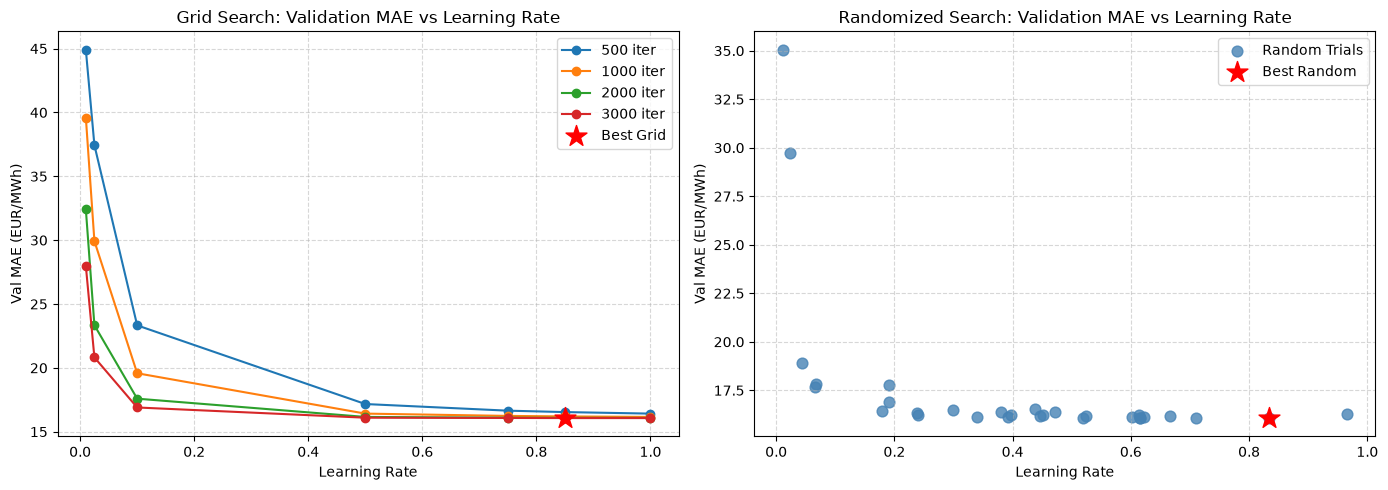

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


for n_iter in iterations_list:
    subset = df_grid[df_grid["Iterations"] == n_iter]
    axes[0].plot(subset["Learning_Rate"], subset["Val_MAE (EUR/MWh)"], marker="o", label=f"{n_iter} iter")

axes[0].scatter(best_row["Learning_Rate"], best_row["Val_MAE (EUR/MWh)"], color="red", marker="*", s=250, zorder=5, label="Best Grid")
axes[0].set_title("Grid Search: Validation MAE vs Learning Rate")
axes[0].set_xlabel("Learning Rate")
axes[0].set_ylabel("Val MAE (EUR/MWh)")
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].scatter(df_random["Learning_Rate"], df_random["Val_MAE (EUR/MWh)"], color="steelblue", s=60, alpha=0.8, label="Random Trials")
axes[1].scatter(best_random_row["Learning_Rate"], best_random_row["Val_MAE (EUR/MWh)"], color="red", marker="*", s=250, zorder=5, label="Best Random")
axes[1].set_title("Randomized Search: Validation MAE vs Learning Rate")
axes[1].set_xlabel("Learning Rate")
axes[1].set_ylabel("Val MAE (EUR/MWh)")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

# Observed vs Simulated, Last week of 2025

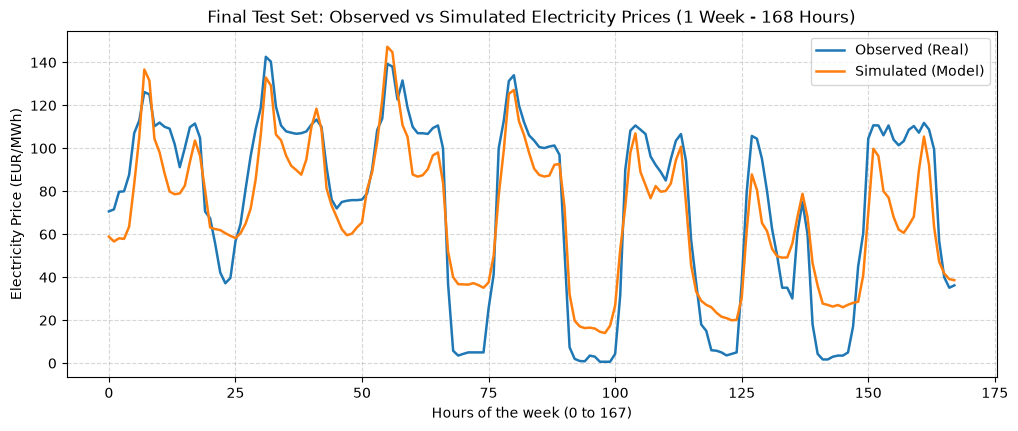

In [19]:

hours_week = np.arange(0, 168, 1)

y_obs_week  = y_test_final_orig[:168]
y_pred_week = y_pred_test_final_eur[:168]

plt.figure(figsize=(12, 4.5))
plt.plot(hours_week, y_obs_week, label="Observed (Real)", linewidth=1.8)
plt.plot(hours_week, y_pred_week, label="Simulated (Model)", linewidth=1.8)

plt.title("Final Test Set: Observed vs Simulated Electricity Prices (1 Week - 168 Hours)")
plt.xlabel("Hours of the week (0 to 167)")
plt.ylabel("Electricity Price (EUR/MWh)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 8 - Feature Importance Study
## 8.1 - Feature Ranking by Model Weights
Since all input features are normalized to the $[0, 1]$ range, we can directly evaluate the importance of each variable by looking at the absolute value of its learned weight ($|w|$). Features with larger absolute weights have a stronger influence on the predicted electricity price, while features with weights close to zero contribute very little to the prediction.

              Feature    Weight  Abs_Weight
      Wind_Onshore_MW -2.076608    2.076608
           Price_t_24  1.398893    1.398893
     Load_Forecast_MW  1.161740    1.161740
             Solar_MW -1.096755    1.096755
          Price_t_168  0.993082    0.993082
  Hydro_Reservoir_MWh -0.484755    0.484755
         Price_24h_MA  0.356212    0.356212
           Price_t_48  0.294448    0.294448
           Is_Weekend -0.199594    0.199594
Nuclear_Generation_MW  0.127684    0.127684
                Month  0.068228    0.068228
                 Hour  0.028171    0.028171


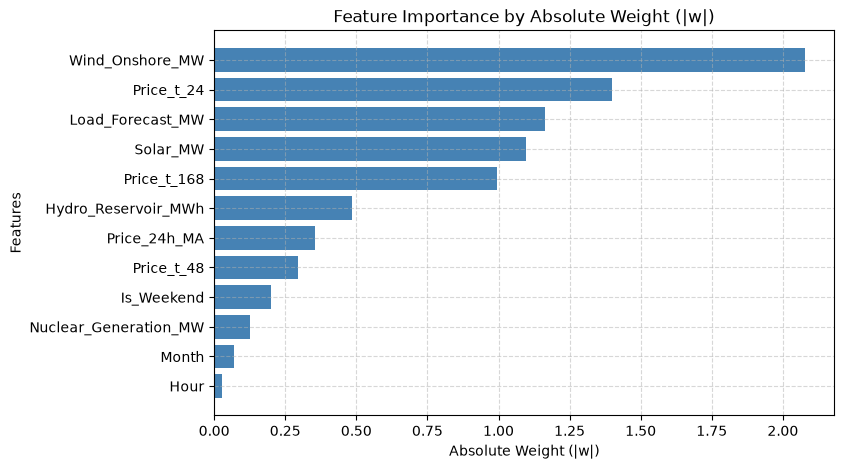

In [20]:
# Calculate absolute weights and sort from most important to least important
importance_df = weights_df.copy()
importance_df["Abs_Weight"] = np.abs(importance_df["Weight"])
importance_df = importance_df.sort_values(by="Abs_Weight", ascending=False)

print(importance_df.to_string(index=False))

# Plot horizontal bar chart of feature importance
plt.figure(figsize=(8, 5))
plt.barh(importance_df["Feature"], importance_df["Abs_Weight"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Feature Importance by Absolute Weight (|w|)")
plt.xlabel("Absolute Weight (|w|)")
plt.ylabel("Features")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 8.2 - Model Training with Selected Features (9 Features)
From the ranking above, we see that the calendar variables (Hour, Month, IsWeekend) have the lowest weights. 

Following the project guidelines, we remove these 3 calendar features (located in the last 3 columns of the dataset) and keep the first 9 features. Note that Nuclear Generation is retained because it is a physical generation source required for the 2030 scenario simulations.

Below, we retrain the Logistic Regression model using the same model() function from Section 5 and the optimal hyperparameters found in Section 7 (best_lr = 0.85, best_iter = 3000).

In [21]:
# Keep only the first 9 features (removing Hour, Month, and Is_Weekend)
train_set_x_reduced = train_set_x_normalized[:9, :]
test_set_x_reduced  = test_set_x_normalized[:9, :]

# Train the logistic regression model with the reduced feature set
logistic_regression_model_reduced = model(
    train_set_x_reduced,
    train_set_y_normalized,
    test_set_x_reduced,
    test_set_y_normalized,
    num_iterations = best_iter,
    learning_rate  = best_lr,
    print_cost = True
)

Cost after iteration 0: 0.693147
Cost after iteration 100: 0.571478
Cost after iteration 200: 0.565820
Cost after iteration 300: 0.564053
Cost after iteration 400: 0.563402
Cost after iteration 500: 0.563144
Cost after iteration 600: 0.563032
Cost after iteration 700: 0.562979
Cost after iteration 800: 0.562950
Cost after iteration 900: 0.562933
Cost after iteration 1000: 0.562921
Cost after iteration 1100: 0.562913
Cost after iteration 1200: 0.562906
Cost after iteration 1300: 0.562902
Cost after iteration 1400: 0.562898
Cost after iteration 1500: 0.562895
Cost after iteration 1600: 0.562893
Cost after iteration 1700: 0.562891
Cost after iteration 1800: 0.562890
Cost after iteration 1900: 0.562889
Cost after iteration 2000: 0.562888
Cost after iteration 2100: 0.562888
Cost after iteration 2200: 0.562887
Cost after iteration 2300: 0.562887
Cost after iteration 2400: 0.562886
Cost after iteration 2500: 0.562886
Cost after iteration 2600: 0.562886
Cost after iteration 2700: 0.562886
Cost

### Cost Function (Reduced Model)
Plot of the cost function across iterations for the 9-feature model.

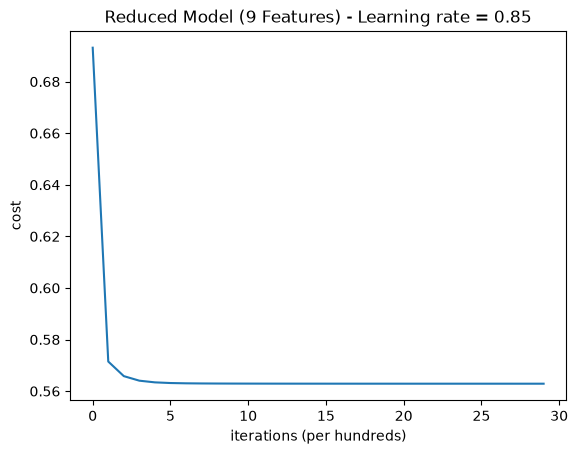

In [22]:
costs_reduced = np.squeeze(logistic_regression_model_reduced["costs"])
plt.plot(costs_reduced)
plt.ylabel("cost")
plt.xlabel("iterations (per hundreds)")
plt.title("Reduced Model (9 Features) - Learning rate = " + str(logistic_regression_model_reduced["learning_rate"]))
plt.show()

### Denormalizing
Reverse the Min-Max normalization to obtain the predicted electricity prices in their original scale (EUR/MWh).

In [23]:
# Reverse the normalization to get the original data
Y_prediction_test_reduced_real_scale = scaler.inverse_transform(logistic_regression_model_reduced["Y_pred_test"])

### Results: Observed vs. Simulated Prices (Reduced Model)
We plot the Observed vs. Simulated electricity prices for the full year 2025 (8,760 hours) and for a 1-week window (168 hours) to clearly inspect the hourly profile.

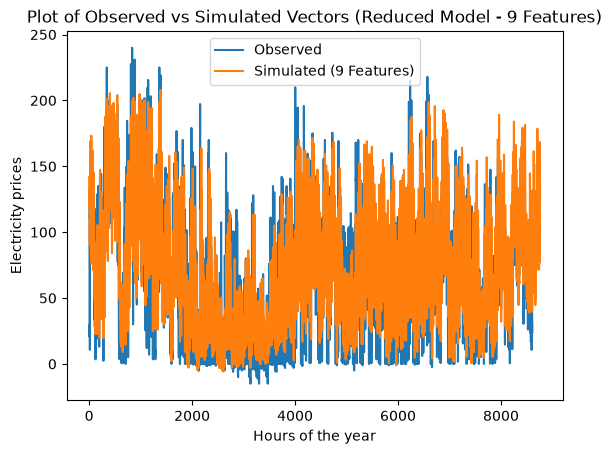

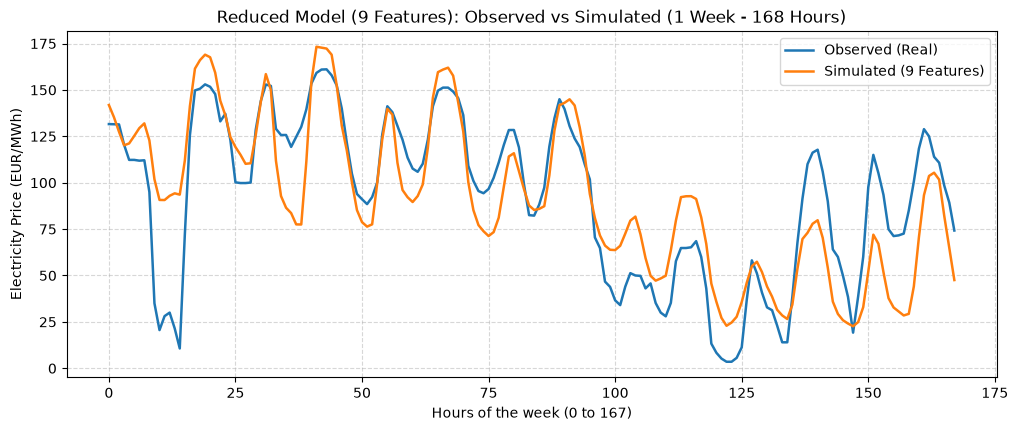

In [24]:
# Define the two vectors
x = np.arange(0, 8760, 1)
y1 = test_set_y_orig
y2 = Y_prediction_test_reduced_real_scale.T

# Plot the vectors for the full year
plt.plot(x, y1, label="Observed")
plt.plot(x, y2, label="Simulated (9 Features)")
plt.title("Plot of Observed vs Simulated Vectors (Reduced Model - 9 Features)")
plt.xlabel("Hours of the year")
plt.ylabel("Electricity prices")
plt.legend()
plt.show()

# Plot 1 week (168 hours) for clearer visualization
hours_week = np.arange(0, 168, 1)
plt.figure(figsize=(12, 4.5))
plt.plot(hours_week, y1[:168], label="Observed (Real)", linewidth=1.8)
plt.plot(hours_week, y2[:168], label="Simulated (9 Features)", linewidth=1.8)
plt.title("Reduced Model (9 Features): Observed vs Simulated (1 Week - 168 Hours)")
plt.xlabel("Hours of the week (0 to 167)")
plt.ylabel("Electricity Price (EUR/MWh)")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

## 8.3 - Performance Comparison: Full Model (12 Features) vs. Reduced Model (9 Features)
Finally, we evaluate the reduced 9-feature model on the **Final Test Set (2nd half of 2025)** and compare its accuracy, MAE, and RMSE directly against the full 12-feature model.

In [25]:
# Slice the Final Test Set (2nd half of 2025) to keep the first 9 features
X_test_final_reduced = X_test_final_norm[:9, :]

# Predict on the Final Test Set using the trained parameters of the reduced model
Y_pred_test_final_reduced = predict(
    logistic_regression_model_reduced["w"],
    logistic_regression_model_reduced["b"],
    X_test_final_reduced
)

test_final_reduced_acc  = 100 - np.mean(np.abs(Y_pred_test_final_reduced - Y_test_final_norm)) * 100
y_pred_test_final_reduced_eur = scaler.inverse_transform(Y_pred_test_final_reduced.T)
test_final_reduced_mae  = np.mean(np.abs(y_pred_test_final_reduced_eur - y_test_final_orig))
test_final_reduced_rmse = np.sqrt(np.mean((y_pred_test_final_reduced_eur - y_test_final_orig) ** 2))

comparison_df = pd.DataFrame([
    {
        "Model": "Full Model (12 Features)",
        "Learning_Rate": best_lr,
        "Iterations": best_iter,
        "Final_Test_Acc (%)": round(test_final_acc, 2),
        "Final_Test_MAE (EUR/MWh)": round(test_final_mae, 2),
        "Final_Test_RMSE (EUR/MWh)": round(test_final_rmse, 2)
    },
    {
        "Model": "Reduced Model (9 Features)",
        "Learning_Rate": best_lr,
        "Iterations": best_iter,
        "Final_Test_Acc (%)": round(test_final_reduced_acc, 2),
        "Final_Test_MAE (EUR/MWh)": round(test_final_reduced_mae, 2),
        "Final_Test_RMSE (EUR/MWh)": round(test_final_reduced_rmse, 2)
    }
])

print(comparison_df.to_string(index=False))

                     Model  Learning_Rate  Iterations  Final_Test_Acc (%)  Final_Test_MAE (EUR/MWh)  Final_Test_RMSE (EUR/MWh)
  Full Model (12 Features)           0.85        3000               93.78                     15.86                      19.71
Reduced Model (9 Features)           0.85        3000               93.84                     15.70                      19.55


### Conclusion
* Removing the 3 low-importance calendar variables (Hour, Month, and Is_Weekend) reduces model complexity from 12 to 9 features while slightly improving test performance:
  * Final Test Accuracy improves from 93.78% to 93.84%.
  * Final Test MAE decreases from 15.86 EUR/MWh to 15.70 EUR/MWh.
  * Final Test RMSE decreases from 19.71 EUR/MWh to 19.55 EUR/MWh.
* This confirms that calendar indicators are redundant once physical generation forecasts (Wind, olar, Load) and lagged prices (Price_t_24, Price_t_168) are included.